# DDM parameter recovery

The review asked for parameter recovery alongside the posterior-predictive checks in `3.50`, because
the DDM is flexible enough that a good fit does not guarantee interpretable parameters. Figure 3's
claim is that the prior acts through the **drift-rate offset** and not the **starting point**, and both
of those shift choices toward one alternative. The claim is only as good as the separation between the
two in recovery.

`scripts/ddm/ddm_recovery.py` takes a stratified sample of 20 sessions (4 each from controls, tremor
OFF, tremor ON, bradykinesia OFF, bradykinesia ON). It simulates synthetic data from each session-colour's
fitted parameters (final model, `leak-1_tc-1`) on that dataset's own coherence sequence, then refits
with the identical pipeline: same parameterisation, bounds, likelihood and differential-evolution
settings. The simulation noise is independent of the fit's common random numbers.

Two arms:

* **fitted**: both colours simulated from their own fitted parameters, so the true colour difference
  (unequal minus equal) is the one the real fits report.
* **null**: the colour-1 coherence sequence simulated from the colour-0 parameters, so every true colour
  difference is zero. Paired with the colour-0 refit, this gives the spread of colour differences the
  pipeline produces when nothing differs.

The fits ran on CPU (the Numba simulator) rather than the cluster GPUs used for Figure 3; simulation and
refit use the same backend, so the recovery is internally consistent.

Outputs go to the gitignored `outputs/` directory.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
import json

from config import dir_config

processed_dir = Path(dir_config.data.processed)
OUTPUT_DIR = (Path.cwd().parent / "outputs").resolve()
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0]))
RECOVERY_DIR = OUTPUT_DIR / "ddm_recovery"

spec = json.loads((RECOVERY_DIR / "jobs.json").read_text())
results = [json.loads(p.read_text()) for p in sorted(RECOVERY_DIR.glob("shards/*.json"))]
print(f"model {spec['model']}: {len(results)} of {len(spec['jobs'])} jobs complete")
assert len(results) == len(spec["jobs"]), "recovery still running"

FREE = ["ndt", "a", "z", "drift_gain", "drift_offset", "sv", "sz", "leak_rate", "time_constant"]
BOUNDS = {"ndt": (0.1, 1.0), "a": (0.5, 2.0), "z": (0.1, 0.9), "drift_gain": (1.0, 10.0), "drift_offset": (-2.0, 2.0),
          "sv": (0.0, 3.0), "sz": (0.0, 0.3), "leak_rate": (0.0, 0.3), "time_constant": (-0.5, 0.5)}
LABELS = {"ndt": "non-decision time", "a": "boundary separation", "z": "starting point", "drift_gain": "drift gain",
          "drift_offset": "drift-rate offset", "sv": "drift variability", "sz": "start-point variability",
          "leak_rate": "leak", "time_constant": "urgency"}

rows = []
for r in results:
    row = {k: r[k] for k in ["job", "session_id", "group", "arm", "data_colour", "param_colour", "n_trials", "n_valid", "success",
                             "sim_p_choice1", "real_p_choice1", "sim_median_rt", "real_median_rt", "fit_seconds"]}
    row.update({f"true_{p}": r["true"][p] for p in FREE})
    row.update({f"rec_{p}": r["recovered"][p] for p in FREE})
    rows.append(row)
rec = pd.DataFrame(rows).sort_values("job").reset_index(drop=True)
print(f"all fits successful: {rec['success'].all()};  simulated trials without a bound crossing: "
      f"{(rec['n_trials'] - rec['n_valid']).sum()} of {rec['n_trials'].sum()}")
print(f"fit time: median {rec['fit_seconds'].median() / 60:.0f} min")
rec.groupby(["group", "arm"]).size().unstack()

model leak-1_tc-1: 60 of 60 jobs complete
all fits successful: True;  simulated trials without a bound crossing: 2 of 18424
fit time: median 13 min


arm,fitted,null
group,,
HC,8,4
bradykinetic_off,8,4
bradykinetic_on,8,4
tremor_off,8,4
tremor_on,8,4


## Part 1. Recovery of each parameter

From the 40 fitted-arm datasets. `normalised RMSE` is the root-mean-square error as a fraction of the
parameter's fitting range, so parameters on different scales can be compared. A parameter is
recovered well when `r` is high, the slope is near 1 and the error is small relative to the range.

In [3]:
fitted = rec[rec["arm"] == "fitted"]
recovery = []
for p in FREE:
    t, e = fitted[f"true_{p}"], fitted[f"rec_{p}"]
    width = BOUNDS[p][1] - BOUNDS[p][0]
    slope = np.polyfit(t, e, 1)[0] if t.std() > 0 else np.nan
    recovery.append({"parameter": p, "label": LABELS[p], "pearson r": stats.pearsonr(t, e).statistic,
                     "spearman rho": stats.spearmanr(t, e).statistic, "slope": slope, "bias": (e - t).mean(),
                     "normalised RMSE": np.sqrt(((e - t) ** 2).mean()) / width,
                     "true SD / range": t.std() / width})
recovery = pd.DataFrame(recovery).set_index("parameter")
recovery.round(3)

,label,pearson r,spearman rho,slope,bias,normalised RMSE,true SD / range
parameter,,,,,,,
ndt,non-decision time,0.948,0.932,0.986,0.011,0.026,0.071
a,boundary separation,0.624,0.628,0.764,-0.040,0.130,0.131
z,starting point,0.915,0.878,1.012,-0.006,0.036,0.081
drift_gain,drift gain,0.924,0.903,1.051,0.378,0.089,0.182
drift_offset,drift-rate offset,0.913,0.873,1.077,0.020,0.057,0.118
sv,drift variability,0.539,0.591,0.741,0.428,0.248,0.174
sz,start-point variability,0.359,0.347,0.432,0.011,0.357,0.286
leak_rate,leak,0.154,0.161,0.135,0.032,0.341,0.268
time_constant,urgency,0.081,0.254,0.408,-0.181,0.280,0.043


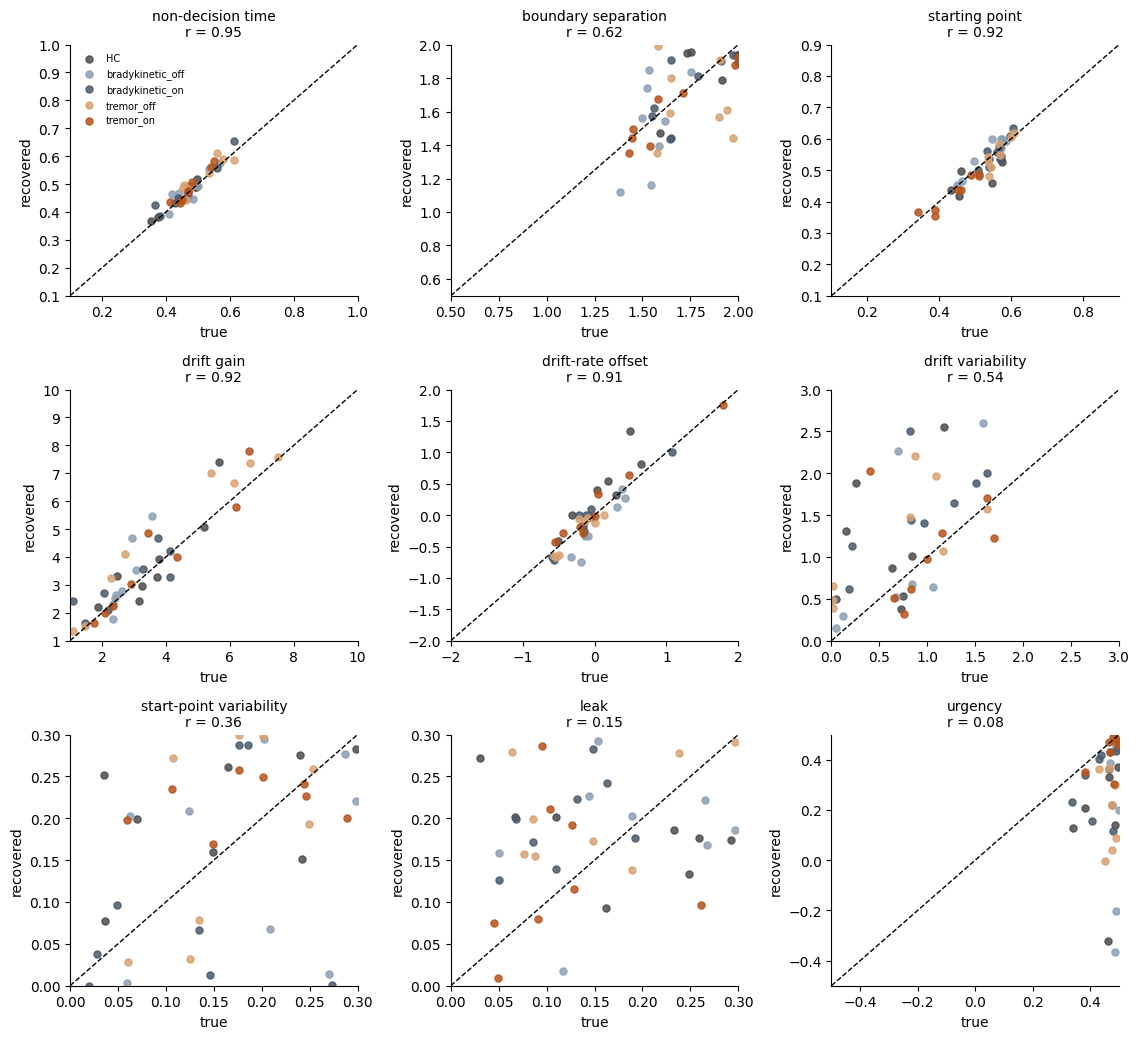

In [4]:
fig, axes = plt.subplots(3, 3, figsize=(11.5, 10.5))
group_colors = {"HC": "#4C4C4C", "tremor_off": "#D9A273", "tremor_on": "#B5541D", "bradykinetic_off": "#8DA0B3", "bradykinetic_on": "#4A5A6B"}
for ax, p in zip(axes.ravel(), FREE):
    for group, block in fitted.groupby("group"):
        ax.scatter(block[f"true_{p}"], block[f"rec_{p}"], s=26, alpha=0.85, color=group_colors[group], label=group)
    lo, hi = BOUNDS[p]
    ax.plot([lo, hi], [lo, hi], color="k", lw=1, ls="--")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_title(f"{LABELS[p]}\nr = {recovery.loc[p, 'pearson r']:.2f}", fontsize=10)
    ax.set_xlabel("true"); ax.set_ylabel("recovered")
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ddm_recovery_parameters.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "ddm_recovery_parameters.png", dpi=200, bbox_inches="tight"); plt.show()

## Part 2. Do starting point and drift offset trade off?

If the two parameters are not separately identifiable, an over-estimate of one comes with an
under-estimate of the other, and their recovery errors correlate negatively. The full error
correlation matrix is shown, with the starting-point / drift-offset pair singled out.

starting point vs drift offset: error correlation rho = -0.63, p = 0.000 (n = 40)


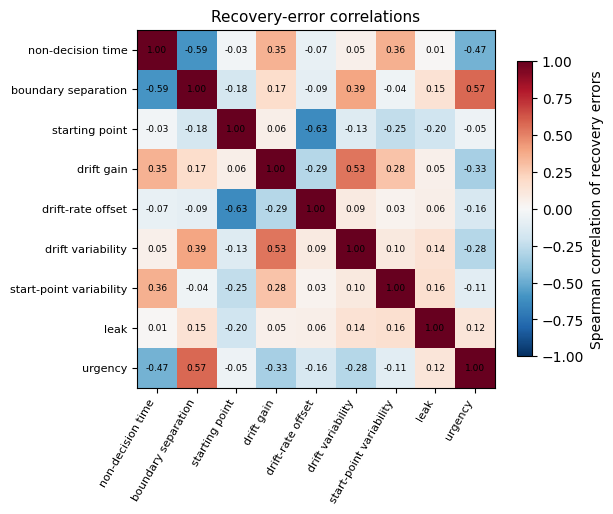

,ndt,a,z,drift_gain,drift_offset,sv,sz,leak_rate,time_constant
ndt,1.00,-0.59,-0.03,0.35,-0.07,0.05,0.36,0.01,-0.47
a,-0.59,1.00,-0.18,0.17,-0.09,0.39,-0.04,0.15,0.57
z,-0.03,-0.18,1.00,0.06,-0.63,-0.13,-0.25,-0.20,-0.05
drift_gain,0.35,0.17,0.06,1.00,-0.29,0.53,0.28,0.05,-0.33
drift_offset,-0.07,-0.09,-0.63,-0.29,1.00,0.09,0.03,0.06,-0.16
sv,0.05,0.39,-0.13,0.53,0.09,1.00,0.10,0.14,-0.28
sz,0.36,-0.04,-0.25,0.28,0.03,0.10,1.00,0.16,-0.11
leak_rate,0.01,0.15,-0.20,0.05,0.06,0.14,0.16,1.00,0.12
time_constant,-0.47,0.57,-0.05,-0.33,-0.16,-0.28,-0.11,0.12,1.00


In [5]:
errors = pd.DataFrame({p: fitted[f"rec_{p}"].to_numpy() - fitted[f"true_{p}"].to_numpy() for p in FREE})
error_corr = errors.corr(method="spearman")
pair = stats.spearmanr(errors["z"], errors["drift_offset"])
print(f"starting point vs drift offset: error correlation rho = {pair.statistic:+.2f}, p = {pair.pvalue:.3f} (n = {len(errors)})")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(error_corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FREE))); ax.set_xticklabels([LABELS[p] for p in FREE], rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(FREE))); ax.set_yticklabels([LABELS[p] for p in FREE], fontsize=8)
for i in range(len(FREE)):
    for j in range(len(FREE)):
        ax.text(j, i, f"{error_corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation of recovery errors")
ax.set_title("Recovery-error correlations", fontsize=11)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ddm_recovery_error_correlation.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "ddm_recovery_error_correlation.png", dpi=200, bbox_inches="tight"); plt.show()
error_corr.round(2)

## Part 3. The colour difference, which is what Figure 3 interprets

Figure 3 tests the within-session difference between colours (unequal minus equal). Recovery of a
parameter's level does not guarantee recovery of a within-session difference, which is smaller and
combines two fits' errors. Two checks:

* **fitted arm**: recovered against true difference, per session;
* **null arm**: the recovered difference when the true difference is zero. Its spread is the noise
  floor of a single session's colour difference, compared with the spread of the differences in the
  real fits.

In [6]:
def colour_difference(frame, arm_colour1, prefix):
    c0 = frame[(frame["arm"] == "fitted") & (frame["data_colour"] == 0)].set_index("session_id")
    c1 = frame[(frame["arm"] == arm_colour1) & (frame["data_colour"] == 1)].set_index("session_id")
    return pd.DataFrame({p: c1[f"{prefix}_{p}"] - c0[f"{prefix}_{p}"] for p in FREE}).join(c0[["group"]])


true_diff = colour_difference(rec, "fitted", "true")
rec_diff = colour_difference(rec, "fitted", "rec")
null_diff = colour_difference(rec, "null", "rec")

ddm_params = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60_ddm_params.csv")
observed_diff = pd.DataFrame({p: ddm_params[f"{p}_prior_cond_1"].astype(float) - ddm_params[f"{p}_prior_cond_0"].astype(float) for p in FREE})

difference_rows = []
for p in ["drift_offset", "z", "drift_gain", "a", "ndt"]:
    difference_rows.append({
        "parameter": LABELS[p],
        "fitted arm: r(true, recovered)": stats.pearsonr(true_diff[p], rec_diff[p]).statistic,
        "fitted arm: slope": np.polyfit(true_diff[p], rec_diff[p], 1)[0],
        "null arm: mean": null_diff[p].mean(),
        "null arm: SD": null_diff[p].std(),
        "real fits: SD over all sessions": observed_diff[p].std(),
        "null SD / real SD": null_diff[p].std() / observed_diff[p].std(),
    })
difference = pd.DataFrame(difference_rows).set_index("parameter")
difference.round(3)

,"fitted arm: r(true, recovered)",fitted arm: slope,null arm: mean,null arm: SD,real fits: SD over all sessions,null SD / real SD
parameter,,,,,,
drift-rate offset,0.924,0.997,0.021,0.338,0.603,0.561
starting point,0.851,0.950,-0.000,0.033,0.049,0.669
drift gain,0.375,0.731,0.045,0.825,0.799,1.032
boundary separation,0.360,0.646,0.001,0.221,0.169,1.307
non-decision time,0.635,0.913,0.001,0.023,0.032,0.724


In [7]:
multiplicity = pd.read_csv(OUTPUT_DIR / "ddm_figure3_multiplicity.csv")
drift = multiplicity[multiplicity["parameter"] == "Drift-rate offset"].copy()
drift["group mean difference"] = drift["unequal"] - drift["equal"]
null_sd = null_diff["drift_offset"].std()
drift["null SE of a group mean"] = null_sd / np.sqrt(drift["n"])
drift["difference / null SE"] = drift["group mean difference"] / drift["null SE of a group mean"]
drift[["group", "n", "group mean difference", "null SE of a group mean", "difference / null SE", "raw p", "BH-FDR"]].round(3)

,group,n,group mean difference,null SE of a group mean,difference / null SE,raw p,BH-FDR
5,Healthy controls,18,0.325,0.080,4.076,0.038,0.192
6,Tremor OFF,11,0.011,0.102,0.107,0.577,0.998
7,Tremor ON,11,0.513,0.102,5.034,0.032,0.192
8,Brady OFF,10,0.115,0.107,1.077,0.846,0.998
9,Brady ON,10,0.265,0.107,2.479,0.160,0.534


The last table puts Figure 3's group-mean drift-offset differences on the scale of the
pipeline's own noise: `null SE of a group mean` is the spread expected for a group of that size if
every participant's true difference were zero, using the null arm's per-session SD. It assumes
independent sessions and ignores real between-participant variation, so it is a floor on the noise,
not a test.

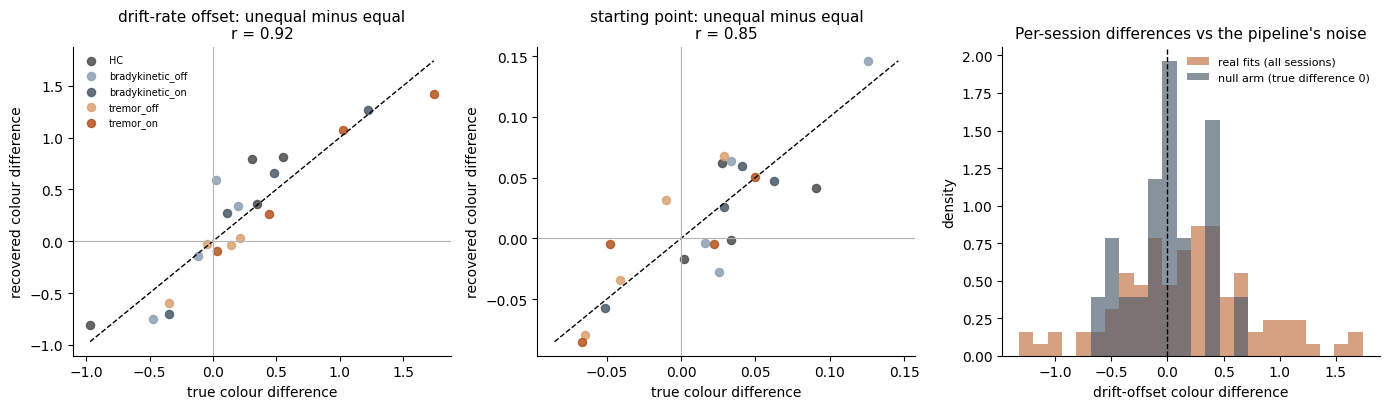

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, p in zip(axes[:2], ["drift_offset", "z"]):
    for group, block in rec_diff.groupby("group"):
        ax.scatter(true_diff.loc[block.index, p], block[p], s=34, color=group_colors[group], label=group, alpha=0.85)
    lims = [min(true_diff[p].min(), rec_diff[p].min()), max(true_diff[p].max(), rec_diff[p].max())]
    ax.plot(lims, lims, color="k", lw=1, ls="--")
    ax.axhline(0, color="0.7", lw=0.8); ax.axvline(0, color="0.7", lw=0.8)
    ax.set_xlabel("true colour difference"); ax.set_ylabel("recovered colour difference")
    ax.set_title(f"{LABELS[p]}: unequal minus equal\nr = {difference.loc[LABELS[p], 'fitted arm: r(true, recovered)']:.2f}", fontsize=11)
axes[0].legend(frameon=False, fontsize=7)

ax = axes[2]
bins = np.linspace(min(observed_diff["drift_offset"].min(), null_diff["drift_offset"].min()),
                   max(observed_diff["drift_offset"].max(), null_diff["drift_offset"].max()), 25)
ax.hist(observed_diff["drift_offset"].dropna(), bins=bins, density=True, color="#B5541D", alpha=0.55, label="real fits (all sessions)")
ax.hist(null_diff["drift_offset"], bins=bins, density=True, color="#4A5A6B", alpha=0.65, label="null arm (true difference 0)")
ax.axvline(0, color="k", lw=1, ls="--")
ax.set_xlabel("drift-offset colour difference"); ax.set_ylabel("density")
ax.set_title("Per-session differences vs the pipeline's noise", fontsize=11); ax.legend(frameon=False, fontsize=8)
for a in axes:
    for sp in ["top", "right"]: a.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "ddm_recovery_colour_difference.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "ddm_recovery_colour_difference.png", dpi=200, bbox_inches="tight"); plt.show()

In [9]:
rec.to_csv(OUTPUT_DIR / "ddm_recovery_fits.csv", index=False)
recovery.to_csv(OUTPUT_DIR / "ddm_recovery_parameters.csv")
error_corr.to_csv(OUTPUT_DIR / "ddm_recovery_error_correlation.csv")
difference.to_csv(OUTPUT_DIR / "ddm_recovery_colour_difference.csv")
drift.to_csv(OUTPUT_DIR / "ddm_recovery_figure3_scale.csv", index=False)
print("saved DDM recovery tables and figures")

saved DDM recovery tables and figures
